# FNEWS EDA — Data Quality and Missingness

Checks text/image presence, labels, duplicate paths, and decodability of processed local images. It does not claim coverage of complete upstream releases.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
while not (ROOT / 'reports' / 'EDA').exists(): ROOT = ROOT.parent
EDA = ROOT / 'reports' / 'EDA'
FIG = EDA / 'figures'
summary = json.loads((EDA / 'eda_summary.json').read_text())
summary

{'verified_pairs': 4233,
 'splits': [{'dataset': 'Fakeddit research-v1',
   'split': 'train',
   'manifest_rows': 1185253,
   'verified_pairs': 2353,
   'text_available': 2353,
   'image_available': 2353,
   'raw_label_1_source_true': 1199,
   'raw_label_0_source_non_true': 1154},
  {'dataset': 'Fakeddit research-v1',
   'split': 'validate',
   'manifest_rows': 124425,
   'verified_pairs': 933,
   'text_available': 933,
   'image_available': 933,
   'raw_label_1_source_true': 377,
   'raw_label_0_source_non_true': 556},
  {'dataset': 'Fakeddit research-v1',
   'split': 'test',
   'manifest_rows': 125115,
   'verified_pairs': 947,
   'text_available': 947,
   'image_available': 947,
   'raw_label_1_source_true': 382,
   'raw_label_0_source_non_true': 565}],
 'readable_images': 4233,
 'corrupt_images': 0,
 'exact_text_cross_split_groups': 19,
 'exact_image_cross_split_groups': 0}

,split,rows,missing_text,empty_text,missing_image_path,duplicate_text_members,duplicate_image_path_members,invalid_label
0,test,947,0,0,0,29,0,0
1,train,2353,0,0,0,54,0,0
2,validate,933,0,0,0,37,0,0


,count
readable,
True,4233


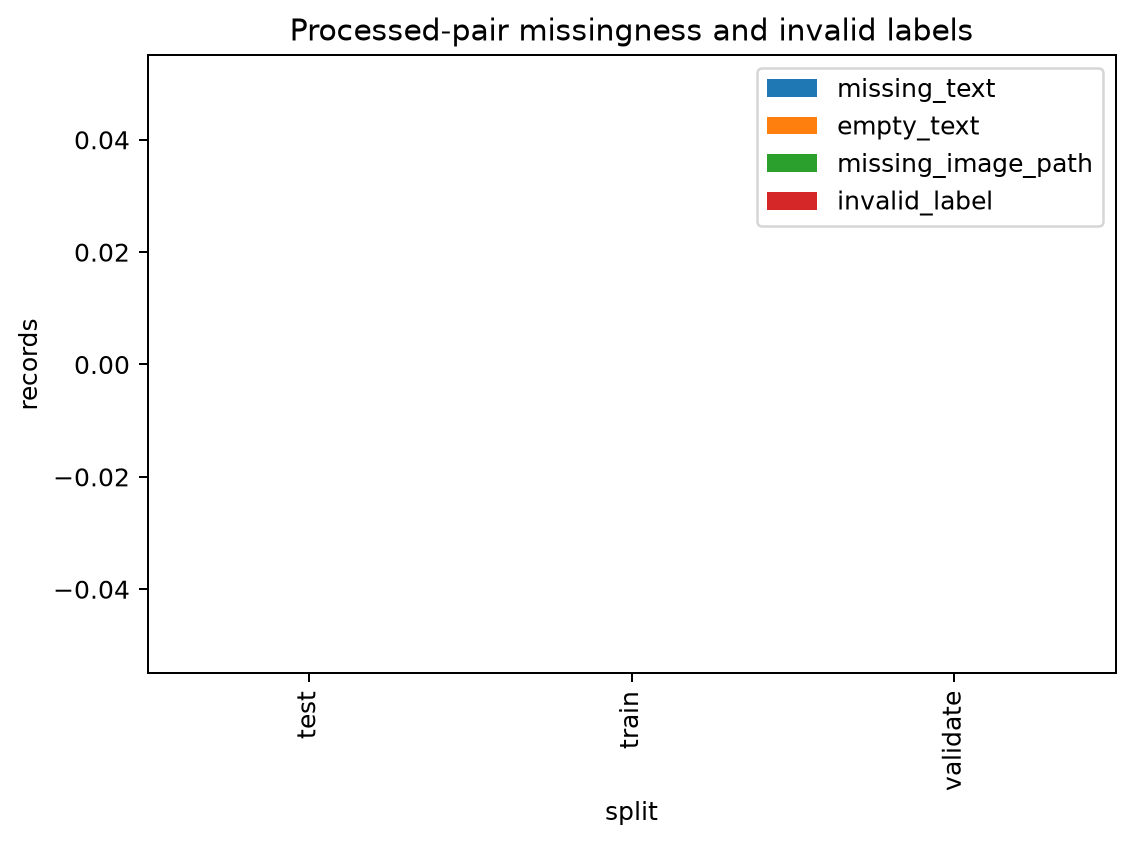

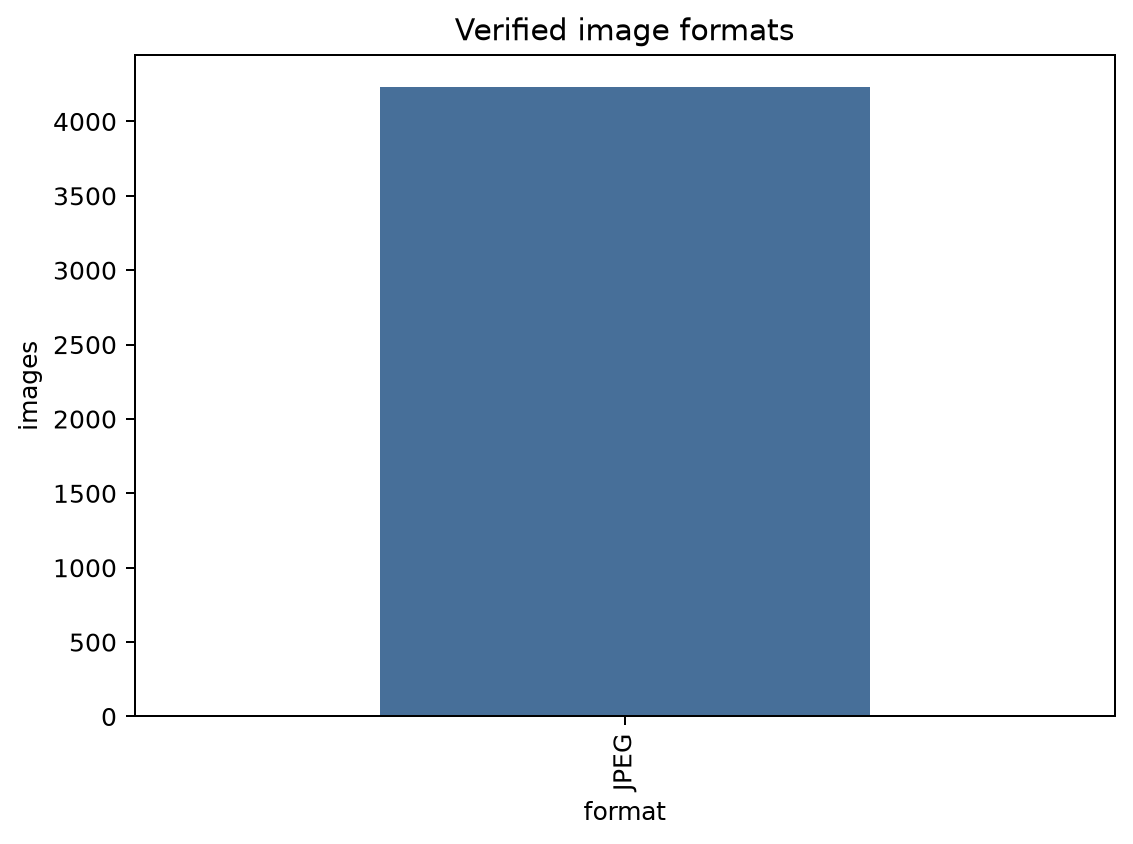

In [2]:
quality=pd.read_csv(EDA/'data_quality_summary.csv'); images=pd.read_csv(EDA/'tables'/'image_features.csv')
display(quality); display(images.readable.value_counts(dropna=False).rename('count').to_frame())
for n in ['03_quality_missingness.png','17_image_formats.png']: display(Image(filename=str(FIG/n)))

### Reproducibility note

Generated from local manifests and processed images by `scripts/run_comprehensive_eda.py`. No external content was fetched and no model training occurred.